In [1]:
import numpy as np
from scipy.stats import binom, binomtest

# Исходные данные
n = 1000
p_baseline = 0.1
k_observed = 113

# --- СПОСОБ 1. Расчет «вручную» (через точное распределение) ---
# Нам нужно найти вероятность получить значение 113 или более экстремальное.
# Матожидание = 1000 * 0.1 = 100. Наблюдаемое значение (113) больше 100, значит это правый хвост.

# Правый хвост: P(X >= 113) = 1 - P(X <= 112)
p_right_tail = 1 - binom.cdf(k_observed - 1, n, p_baseline)

# Так как альтернатива двусторонняя, нам нужно учесть симметричный левый хвост.
# Ищем точку в левом хвосте, которая столь же или более «удалена» от матожидания (100).
# Отклонение вправо: 113 - 100 = 13. Значит, отклонение влево: 100 - 13 = 87.
# Левый хвост — это вероятность получить 87 успехов или меньше: P(X <= 87)
p_left_tail = binom.cdf(100 - (k_observed - 100), n, p_baseline)

p_value_manual = p_right_tail + p_left_tail
print(f"p-value (ручной расчет через cdf): {p_value_manual:.5f}")


# --- СПОСОБ 2. Библиотечный точный метод (binomtest) ---
# Он считает абсолютно строго и автоматически учитывает несимметричность хвостов, 
# если они возникают в биномиальном распределении.
res = binomtest(k=k_observed, n=n, p=p_baseline, alternative='two-sided')

print(f"p-value (библиотечный метод):     {res.pvalue:.5f}")

p-value (ручной расчет через cdf): 0.18734
p-value (библиотечный метод):     0.17051


In [3]:
import scipy.stats as stats
p_value = 2 * (1 - stats.t.cdf(1.9512, df=99))
print(f"p-value (t-test approximation): {p_value:.5f}")

p-value (t-test approximation): 0.05386


In [4]:
from sklearn.datasets import fetch_california_housing

data = fetch_california_housing(as_frame=True, return_X_y=True)
df, target = data[0], data[1] 

In [5]:
df.describe()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude
count,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,3.870671,28.639486,5.429000,1.096675,1425.476744,3.070655,35.631861,-119.569704
std,1.899822,12.585558,2.474173,0.473911,1132.462122,10.386050,2.135952,2.003532
min,0.499900,1.000000,0.846154,0.333333,3.000000,0.692308,32.540000,-124.350000
25%,2.563400,18.000000,4.440716,1.006079,787.000000,2.429741,33.930000,-121.800000
50%,3.534800,29.000000,5.229129,1.048780,1166.000000,2.818116,34.260000,-118.490000
75%,4.743250,37.000000,6.052381,1.099526,1725.000000,3.282261,37.710000,-118.010000
max,15.000100,52.000000,141.909091,34.066667,35682.000000,1243.333333,41.950000,-114.310000


In [6]:
# Выделяем целевой признак для сравнения (доходы — MedInc) по условию возраста (HouseAge)
group_young = df[df['HouseAge'] <= 30]['MedInc']
group_old = df[df['HouseAge'] > 30]['MedInc']

# Проводим t-тест Уэлча (независимый t-критерий с equal_var=False)
t_stat, p_value = stats.ttest_ind(group_young, group_old, equal_var=False, alternative='two-sided')

print(f"t-статистика: {t_stat}")
print(f"p-value: {p_value}")

t-статистика: 12.832590060636964
p-value: 1.5106543204696105e-37


--- Дома <= 30 лет ---
Тест Шапиро-Уилка (на 5000 наблюдениях): p-value = 1.9563238756714428e-47
Вывод теста: Данные распределены НЕ нормально (отвергаем H0)


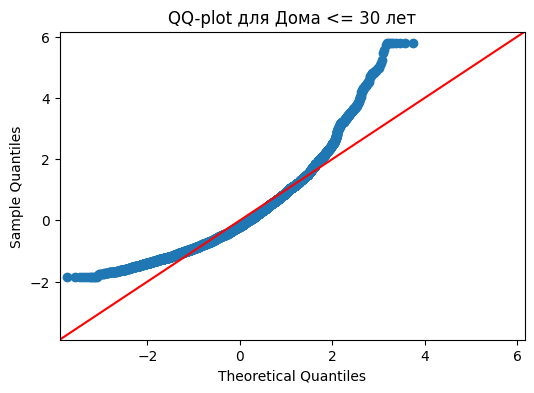

--- Дома > 30 лет ---
Тест Шапиро-Уилка (на 5000 наблюдениях): p-value = 3.9857577518092373e-57
Вывод теста: Данные распределены НЕ нормально (отвергаем H0)


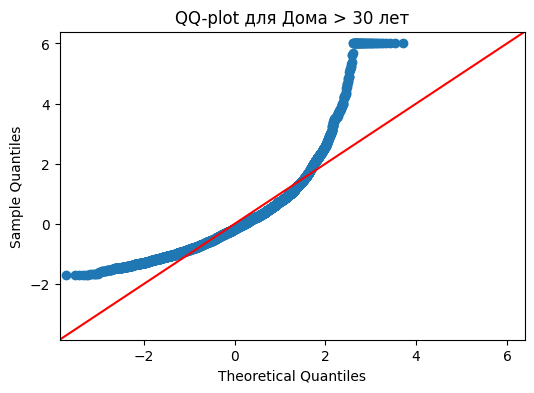

In [8]:
import statsmodels.api as sm
import matplotlib.pyplot as plt

def analyze_normality(data_series, group_name):
    # Стандартизируем данные вручную для правильного отображения sm.qqplot
    standardized_data = (data_series - data_series.mean()) / data_series.std()
    
    # Запускаем тест Шапиро-Уилка
    # (Берем первые 5000 элементов, так как тест Шапиро-Уилка в scipy ограничен по размеру выборки)
    shapiro_stat, shapiro_p = stats.shapiro(standardized_data[:5000])
    print(f"--- {group_name} ---")
    print(f"Тест Шапиро-Уилка (на 5000 наблюдениях): p-value = {shapiro_p}")
    if shapiro_p < 0.05:
        print("Вывод теста: Данные распределены НЕ нормально (отвергаем H0)")
    else:
        print("Вывод теста: Нет оснований отвергнуть нормальность (принимаем H0)")
        
    # Строим QQ-plot
    fig, ax = plt.subplots(figsize=(6, 4))
    sm.qqplot(standardized_data, line='45', ax=ax)
    ax.set_title(f"QQ-plot для {group_name}")
    plt.show()

# 4. Запускаем анализ для обеих выборок
analyze_normality(group_young, "Дома <= 30 лет")
analyze_normality(group_old, "Дома > 30 лет")

--- Дома <= 30 лет после логарифмирования ---
p-value теста Шапиро-Уилка: 2.0418138826631168e-07


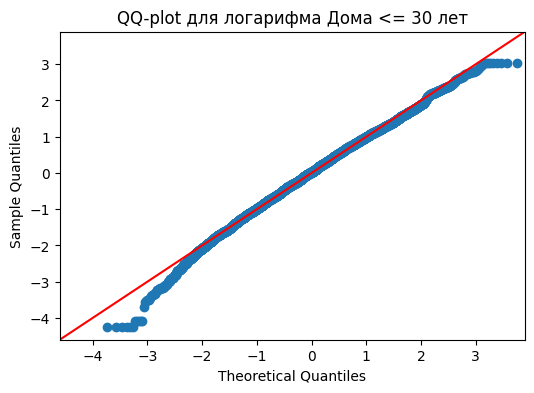

--- Дома > 30 лет после логарифмирования ---
p-value теста Шапиро-Уилка: 1.3542078649836346e-11


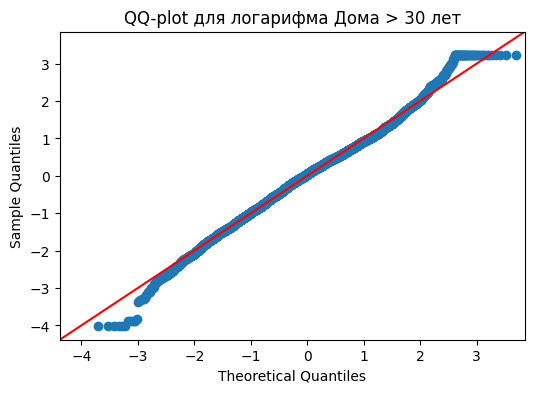

In [9]:
def analyze_log_normality(data_series, group_name):
    # Применяем логарифмирование
    log_data = np.log(data_series)
    
    # Стандартизируем логарифмированные данные (среднее=0, дисперсия=1)
    standardized_log_data = (log_data - log_data.mean()) / log_data.std()
    
    # Тест Шапиро-Уилка (ограничение scikit-learn/scipy на первые 5000 элементов)
    shapiro_stat, shapiro_p = stats.shapiro(standardized_log_data[:5000])
    print(f"--- {group_name} после логарифмирования ---")
    print(f"p-value теста Шапиро-Уилка: {shapiro_p}")
    
    # Строим график QQ-plot
    fig, ax = plt.subplots(figsize=(6, 4))
    sm.qqplot(standardized_log_data, line='45', ax=ax)
    ax.set_title(f"QQ-plot для логарифма {group_name}")
    plt.show()

# 3. Запускаем анализ
analyze_log_normality(group_young, "Дома <= 30 лет")
analyze_log_normality(group_old, "Дома > 30 лет")